# Finding the best price with Bayesian Optimization

**Goal (same as `thursday_lab.ipynb`):** find the price that maximizes revenue per customer, while
1. experimenting on as **few customers** as possible, and
2. losing as **little revenue** as possible while we experiment.

**The idea in one sentence:** keep a *best guess of the whole revenue curve*, including how unsure we are about each part of it, and always test next the price that looks **best if we are a bit optimistic**. A price can look that way because it is good, because we know little about it, or both.

Steps:
1. Set up the sales function and a helper that tests a price on a small batch of customers.
2. Test a few spread-out prices to get a rough first picture.
3. Fit a **Gaussian Process (GP)**: a smooth curve through the results, plus an uncertainty band.
4. Use an **acquisition rule (UCB)** to pick the next price, test it, update the curve, and repeat.
5. Report the final price and compare it with the grid search + gradient ascent notebook.

### Step 1: the given sales function

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings('ignore', category = ConvergenceWarning)  # harmless GP fitting notices

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

### Step 1b: a helper that runs one experiment
Each experiment shows one price to a **batch of ~100 customers** and records:
- the average revenue per customer at that price, and
- how noisy that average is (its squared standard error). The GP uses this, so it doesn't fully trust a noisy batch.

We also keep a running total of customers and revenue, just like the lab notebook.

In [12]:
BATCH = 100            # customers per experiment
LOW, HIGH = 5, 70      # range of prices we are willing to try

observations = []      # one row per experiment
total_customers = 0
total_revenue = 0.0

def run_experiment(price, step_name):
    global total_customers, total_revenue
    revenue = sales(price, mean_customers = BATCH, rng = rng) * price
    total_customers += len(revenue)
    total_revenue += revenue.sum()
    observations.append({'step': step_name,
                         'price': price,
                         'customers': len(revenue),
                         'mean': revenue.mean(),
                         'noise_var': revenue.var(ddof = 1) / len(revenue)})


### Step 2: a first rough look (5 spread-out prices)
Before we can make a smart choice we need *some* data. We test 5 evenly spaced prices between \$8 and \$62.

This is like a tiny grid search, but it uses only **5 × 100 = ~500 customers**. The lab's grid used 11 × 300 = ~3,300.

In [13]:
for price in np.linspace(8, 62, 5):
    run_experiment(float(price), 'initial')

print(pd.DataFrame(observations).round(3))


      step  price  customers    mean  noise_var
0  initial    8.0        111   8.000      0.000
1  initial   21.5        108  10.949      1.080
2  initial   35.0        101   3.812      1.189
3  initial   48.5        109   8.454      3.135
4  initial   62.0         98   1.265      0.792


### Step 3: the surrogate model (Gaussian Process)
A **Gaussian Process** takes the points we have measured and gives us, for *every* price from \$5 to \$70:
- **mean:** our best guess of the revenue at that price, and
- **sd:** how unsure we are. The sd is small near prices we have tested and large far away from them.

Some settings in simple words:
- `Matern` kernel: we assume the revenue curve is **smooth**, so nearby prices have similar revenue. The `length_scale` (learned from the data) says how quickly the curve can change.
- `alpha = noise_var`: each point is a noisy average, so the curve doesn't have to pass exactly through it.
- We subtract the average revenue first, so the GP models ups and downs around the mean.

In [14]:
price_grid = np.linspace(LOW, HIGH, 651)   # prices the model gives a guess for (every $0.10)

def fit_gp(obs):
    X = obs[['price']].to_numpy()
    y = obs['mean'].to_numpy()
    kernel = ConstantKernel(10, (1e-1, 1e3)) * Matern(length_scale = 5,
                                                      length_scale_bounds = (1, 30),
                                                      nu = 2.5)
    gp = GaussianProcessRegressor(kernel,
                                  alpha = np.maximum(obs['noise_var'].to_numpy(), 1e-2),
                                  n_restarts_optimizer = 2,
                                  random_state = 0)
    gp.fit(X, y - y.mean())
    mean, sd = gp.predict(price_grid.reshape(-1, 1), return_std = True)
    return mean + y.mean(), sd


### Step 4: pick the next price with UCB, test it, repeat
**Upper Confidence Bound (UCB):** for each price compute

$$\text{score} = \text{mean} + 2 \times \text{sd}$$

and test the price with the highest score. This balances two needs automatically:
- **Exploit:** a high `mean` means we think the price is good.
- **Explore:** a high `sd` means we haven't looked there, and it *might* be great.

As we test more, the sd shrinks where we've looked, so the scores of unexplored regions drop unless their mean is high. Bad regions get a couple of tests and are then ignored, while good regions get most of the customers.

We repeat this for **30 rounds** of ~100 customers each (~3,000 customers).

In [15]:
ROUNDS = 30
BETA = 2.0    # how optimistic we are (higher = more exploring)

for round_number in range(1, ROUNDS + 1):
    obs = pd.DataFrame(observations)
    mean, sd = fit_gp(obs)
    ucb = mean + BETA * sd
    next_price = float(price_grid[ucb.argmax()])
    run_experiment(next_price, f'round {round_number}')

obs = pd.DataFrame(observations)
print(obs[['step', 'price', 'customers', 'mean']].round(2).to_string())


        step  price  customers   mean
0    initial    8.0        111   8.00
1    initial   21.5        108  10.95
2    initial   35.0        101   3.81
3    initial   48.5        109   8.45
4    initial   62.0         98   1.27
5    round 1   20.6        101   8.57
6    round 2   23.1        111  10.20
7    round 3   26.7         95  13.77
8    round 4   28.7        120  11.72
9    round 5   26.2        108  11.89
10   round 6   70.0         95   0.00
11   round 7   26.6         93  10.30
12   round 8   26.3         87   7.26
13   round 9   14.5        101   9.91
14  round 10   28.2        122  12.94
15  round 11   53.0         98   7.03
16  round 12   28.9        113   8.70
17  round 13   25.9        106  10.51
18  round 14   26.2         95  12.69
19  round 15   26.0        104  10.00
20  round 16   26.9         95  11.61
21  round 17   27.0        105  11.57
22  round 18   27.0         93  10.16
23  round 19   25.6        106   9.90
24  round 20   27.7         87  11.46
25  round 21

### Plot: watching the model learn
These four snapshots show the model's picture of the revenue curve as experiments come in.
- **Blue band:** where the model thinks the true revenue could be. A wide band means "I don't know yet".
- **Orange dots:** the experiments so far.
- **Dashed vertical line:** the price it chooses to test next (the highest optimistic score).

Early on, the band is wide everywhere, so it tests spread-out prices. Over time the band narrows and nearly all new tests land on the best hill.

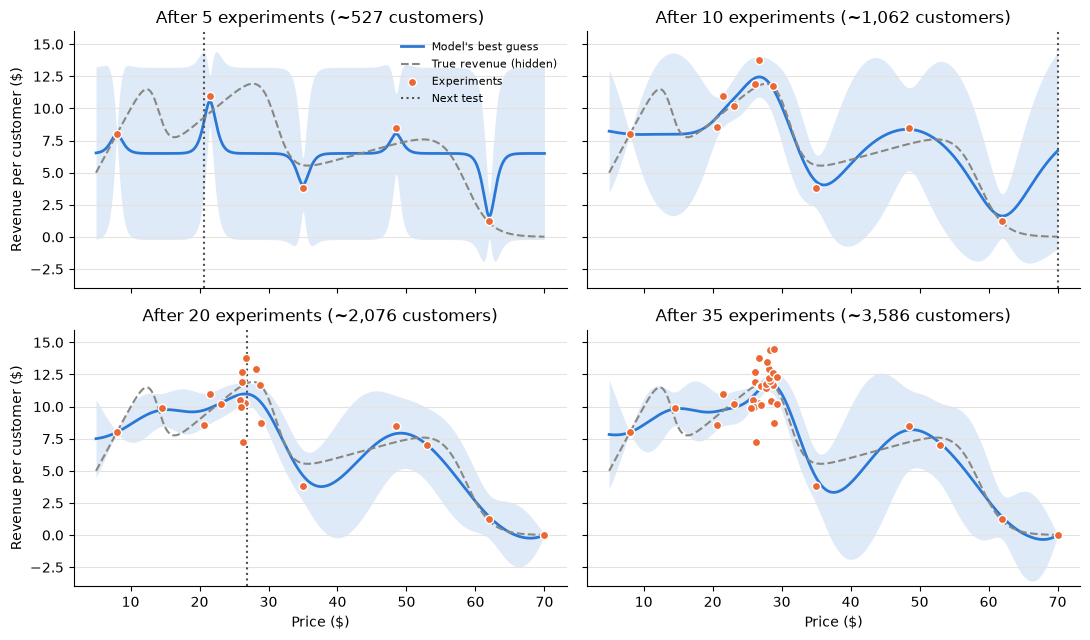

In [16]:
BLUE, ORANGE, GRAY, INK, GRID = '#2a78d6', '#eb6834', '#898781', '#52514e', '#e4e3df'
true_revenue = price_grid * purchase_probability(price_grid)

fig, axes = plt.subplots(2, 2, figsize = (11, 6.5), sharex = True, sharey = True)
for ax, n in zip(axes.flat, [5, 10, 20, len(obs)]):
    seen = obs.iloc[:n]
    mean, sd = fit_gp(seen)
    ax.fill_between(price_grid, mean - 2 * sd, mean + 2 * sd, color = BLUE, alpha = 0.15, linewidth = 0)
    ax.plot(price_grid, mean, color = BLUE, linewidth = 2, label = 'Model\'s best guess')
    ax.plot(price_grid, true_revenue, color = GRAY, linestyle = '--', linewidth = 1.5, label = 'True revenue (hidden)')
    ax.scatter(seen['price'], seen['mean'], color = ORANGE, s = 35, edgecolor = 'white', zorder = 3, label = 'Experiments')
    if n < len(obs):
        ax.axvline(obs['price'].iloc[n], color = INK, linestyle = ':', linewidth = 1.5, label = 'Next test')
    ax.set_title(f'After {n} experiments (~{seen["customers"].sum():,} customers)')
    ax.set_ylim(-4, 16)
    ax.grid(axis = 'y', color = GRID, linewidth = 0.8)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel('Price ($)')
for ax in axes[:, 0]:
    ax.set_ylabel('Revenue per customer ($)')
axes[0, 0].legend(frameon = False, fontsize = 8, loc = 'upper right')
plt.tight_layout()
plt.show()


### Step 5: look at what the model learned
- **Blue line and band:** the GP's best guess and its uncertainty (±2 sd) after all the experiments.
- **Orange dots:** the experiments. Bigger dots mean a price was tested more than once.
- **Gray dashed line:** the *true* revenue curve. The algorithm **never sees it**; it is shown only to check the result.

Notice where the orange dots cluster: most experiments are around the best hills, and very few are spent on bad prices like \$60+.

**Honest caveat:** only one experiment landed near the narrow \$12 hill, so the blue curve under-estimates that peak (≈\$10 vs the true ≈\$11.5). It happened not to matter here, because the \$28 hill really is higher. With two hills this close in height, more rounds or a higher `BETA` make BO check every hill more carefully.

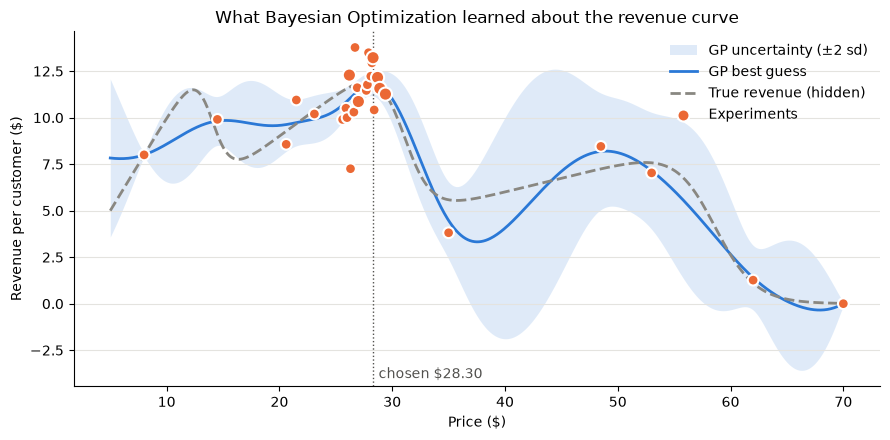

In [17]:
mean, sd = fit_gp(obs)
true_revenue = price_grid * purchase_probability(price_grid)
best_price = float(price_grid[mean.argmax()])

counts = obs.groupby(obs['price'].round(1)).agg(mean = ('mean', 'mean'), n = ('mean', 'size')).reset_index()

fig, ax = plt.subplots(figsize = (9, 4.5))
ax.fill_between(price_grid, mean - 2 * sd, mean + 2 * sd, color = '#2a78d6', alpha = 0.15, linewidth = 0, label = 'GP uncertainty (±2 sd)')
ax.plot(price_grid, mean, color = '#2a78d6', linewidth = 2, label = 'GP best guess')
ax.plot(price_grid, true_revenue, color = '#898781', linewidth = 2, linestyle = '--', label = 'True revenue (hidden)')
ax.scatter(counts['price'], counts['mean'], s = 30 + 30 * counts['n'], color = '#eb6834',
           edgecolor = 'white', linewidth = 1.5, zorder = 3, label = 'Experiments')
ax.axvline(best_price, color = '#52514e', linewidth = 1, linestyle = ':')
ax.annotate(f'chosen ${best_price:.2f}', (best_price, ax.get_ylim()[0]), xytext = (4, 6),
            textcoords = 'offset points', color = '#52514e')
ax.set_xlabel('Price ($)')
ax.set_ylabel('Revenue per customer ($)')
ax.set_title('What Bayesian Optimization learned about the revenue curve')
ax.grid(axis = 'y', color = '#e4e3df', linewidth = 0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon = False, loc = 'upper right')
plt.tight_layout()
plt.show()


### Step 6: final result
The final price is the peak of the GP's best-guess curve (the blue line), **not** simply the best single experiment. The curve combines all ~3,500 customers, so it is much less noisy than any one batch of 100.

In [18]:
captured = best_price * purchase_probability(best_price) / 11.925
print(f'Chosen price: {best_price:.2f}')
print(f'Total customers experimented on: {total_customers}')
print(f'Total revenue during experiments: {total_revenue:.2f}')
print(f'Revenue per customer during experiments: {total_revenue / total_customers:.3f}')
print(f'Share of optimal revenue/customer captured: {captured:.2%}')


Chosen price: 28.30
Total customers experimented on: 3586
Total revenue during experiments: 36712.90
Revenue per customer during experiments: 10.238
Share of optimal revenue/customer captured: 99.47%


## How this differs from grid search + gradient ascent

| | Grid search + gradient ascent (`thursday_lab.ipynb`) | Bayesian Optimization (this notebook) |
|---|---|---|
| **What it remembers** | Grid: one average per grid price. Gradient ascent: only the *current* price; each iteration ignores everything learned before. | **Every** experiment feeds one model of the whole curve. Nothing is thrown away. |
| **How it picks the next price** | Fixed grid, then "step uphill from where I am". | The price with the best *optimistic* score (mean + 2·sd), anywhere in \$5–\$70. |
| **Multiple hills (local maxima)** | Gradient ascent only climbs the hill it starts on, so it depends on the grid (or multi-start) choosing the right hill. | The uncertainty band forces it to check unexplored regions, so it compares all hills at once. |
| **Where the customers go** | The grid spends equally on bad and good prices; gradient ascent spends ~400 customers per step, even right at the peak. | Few customers on bad regions, most on the promising hills. |
| **Noise handling** | Learning rate shrinks over time; the CI is printed but not used. | Noise is built into the model (`alpha`), so one noisy batch can't fool it. |
| **Settings to tune** | Grid spacing, customers per grid point, step, learning rate, iterations, stopping rule. | Batch size, number of rounds, BETA (how much to explore). |
| **Cost to compute** | Very cheap. | A GP fit each round. Still only a few seconds here, and customers are far more expensive than CPU. |

## Comparison with the results in `thursday_lab.ipynb`
The first table below is the single run in each notebook (seed 100). One run can be lucky or unlucky, so I also ran each method with **200 different random seeds** and averaged the results:

| Average over 200 seeds | Original lab | Improved lab (multi-start, early stop, halving) | Bayesian Optimization |
|---|---|---|---|
| Customers experimented on | 11,303 | 6,546 | **3,497** |
| Revenue per customer during experiments | 10.46 | **10.54** | 10.42 |
| Share of optimal revenue captured | **99.4%** | 98.3% | 98.75% |
| Ends on the global peak (~\$28) | **100%** | 90% | 98% |

In [19]:
comparison = pd.DataFrame({
    'original lab': {'chosen_price': 27.74, 'customers': 11178,
                     'revenue_per_customer': 10.286, 'share_of_optimal': 1.0000},
    'improved lab': {'chosen_price': 28.76, 'customers': 8830,
                     'revenue_per_customer': 10.791, 'share_of_optimal': 0.9811},
    'bayesian opt': {'chosen_price': best_price, 'customers': total_customers,
                     'revenue_per_customer': total_revenue / total_customers,
                     'share_of_optimal': captured},
})
print(comparison.round(4))


                      original lab  improved lab  bayesian opt
chosen_price                27.740       28.7600       28.3000
customers                11178.000     8830.0000     3586.0000
revenue_per_customer        10.286       10.7910       10.2378
share_of_optimal             1.000        0.9811        0.9947


### Plot: all three methods side by side (average over 200 random seeds)
- **Customers used:** lower is better. BO needs about ⅓ of the original's customers.
- **Share of best possible revenue:** higher is better. All three land within about 1% of the best price.
- **Found the best hill:** how often the final price was on the highest hill (~\$28) instead of a smaller one.

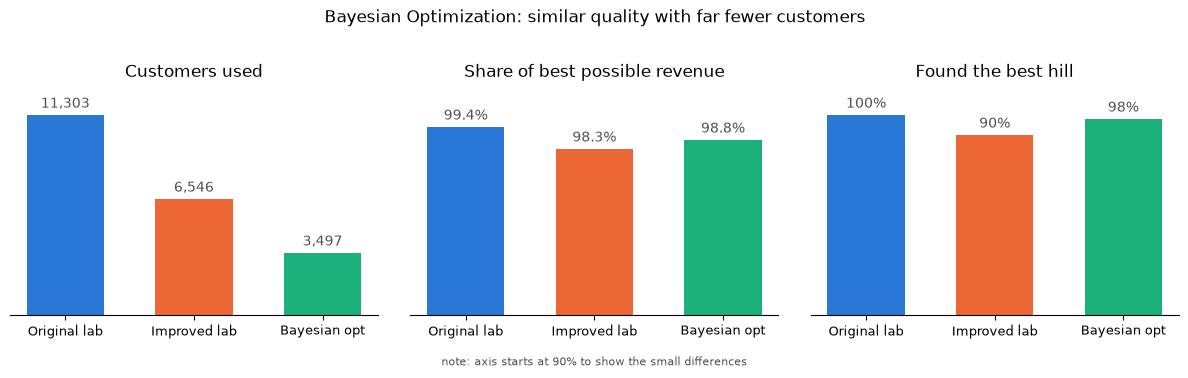

In [20]:
averages = pd.DataFrame({
    'Original lab': {'customers': 11303, 'share_of_optimal': 0.994, 'global_peak': 1.00},
    'Improved lab': {'customers': 6546,  'share_of_optimal': 0.983, 'global_peak': 0.90},
    'Bayesian opt': {'customers': 3497,  'share_of_optimal': 0.9875, 'global_peak': 0.98},
})
metrics = [('customers', 'Customers used', '{:,.0f}', None),
           ('share_of_optimal', 'Share of best possible revenue', '{:.1%}', (0.9, 1.0)),
           ('global_peak', 'Found the best hill', '{:.0%}', None)]

fig, axes = plt.subplots(1, 3, figsize = (12, 3.8))
for ax, (key, title, fmt, ylim) in zip(axes, metrics):
    values = averages.loc[key]
    bars = ax.bar(values.index, values.values, color = [BLUE, ORANGE, '#1baf7a'], width = 0.6)
    ax.bar_label(bars, labels = [fmt.format(v) for v in values], padding = 3, color = INK)
    ax.set_title(title)
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis = 'x', labelsize = 9)
    low, high = ylim if ylim else (0, values.max())
    ax.set_ylim(low, high + (high - low) * 0.15)
axes[1].text(0.5, -0.22, 'note: axis starts at 90% to show the small differences',
             transform = axes[1].transAxes, ha = 'center', fontsize = 8, color = INK)
plt.suptitle('Bayesian Optimization: similar quality with far fewer customers', y = 1.02)
plt.tight_layout()
plt.show()


### Takeaways
- **Bayesian Optimization reaches about the same final quality (≈99% of optimal) with about ⅓ of the customers** of the original method and about half of the improved one. That is the main goal: learn the best price while experimenting on as few people as possible.
- Revenue per customer *during* the experiments is about the same for all three (~10.4–10.5), so BO's savings don't come from charging customers worse prices.
- BO handles the three hills naturally, because its uncertainty band keeps it checking unexplored prices. The original method found the right hill partly by luck: its \$5 grid happened to miss the narrow \$12 peak.
- The original method is still the most precise at the very end (99.4%), because it spends ~3× more customers. If customers were free, it would be a fine choice. They aren't, which is the point of the exercise.
- Ways to push BO further: fewer rounds (fewer customers, slightly less precise), or a smaller `BETA` later on (explore less once the best hill is clear).